Scan through multiple equilibria and find ne pedestal

In [1]:
import sys
import gc
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import importlib.util

# Put repo root on path so `src` is importable (parent of this notebook's parent).
ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(ROOT))

from escape.solver import saarelma_connor


# For Firedrake Model
# Run from `tests/` (so `ROOT` points at the repo). Requires Firedrake +
# parent-class deps (OpenFUSIONToolkit, eqdsk/p-file inputs).
INPUT_DIR = ROOT / "src" / "inputs" / "PT_Hmode"
MHD_FP = INPUT_DIR / "g150840.03000"
KPROF_FP = INPUT_DIR / "p150840.03000"

# `solver-firedrake.py` has a hyphen — load by file path.
_fd_spec = importlib.util.spec_from_file_location(
    "solver_firedrake",
    ROOT / "src" / "solver-firedrake.py",
)
_fd_mod = importlib.util.module_from_spec(_fd_spec)
_fd_spec.loader.exec_module(_fd_mod)
saarelma_connor_firedrake = _fd_mod.saarelma_connor_firedrake


firedrake:WARNING OMP_NUM_THREADS is not set or is set to a value greater than 1, we suggest setting OMP_NUM_THREADS=1 to improve performance


In [2]:
# Discover all g/p file pairs in the PT_Hmode inputs folder.
inputs_dir = ROOT / 'src' / 'inputs' / 'PT_Hmode'

g_files = sorted(inputs_dir.glob('g*'))
p_files = sorted(inputs_dir.glob('p*'))

# Match g and p files by their shared suffix (everything after the leading 'g'/'p').
g_by_suffix = {f.name[1:]: f for f in g_files}
p_by_suffix = {f.name[1:]: f for f in p_files}
shared_suffixes = sorted(set(g_by_suffix) & set(p_by_suffix))

equilibria = [(str(g_by_suffix[s]), str(p_by_suffix[s])) for s in shared_suffixes]

print(f"Found {len(equilibria)} g/p file pairs in {inputs_dir}:")
for mhd_fp, kprof_fp in equilibria:
    print(f"  g: {mhd_fp}\n  p: {kprof_fp}")

Found 10 g/p file pairs in /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode:
  g: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/g150840.03000
  p: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/p150840.03000
  g: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/g152960.03500
  p: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/p152960.03500
  g: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/g153100.03000
  p: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/p153100.03000
  g: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/g153140.04750
  p: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/p153140.04750
  g: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/g153303.03100
  p: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/p153303.03100
  g: /Users/nelsonlab/codes/saarelma-conner-ped/src/inputs/PT_Hmode/g153440.01725
  p: /U

FIREDRAKE Model

In [3]:
# Scan size (each dimension has N points)
N = 5

# Scan parameters
# alpha_crits = np.linspace(0.01, 2.0, 3)
# C_KBMs = np.linspace(0.01, 0.9, 3)
# De_chie_etgs = np.linspace(0.01, 0.9, 3)
# nFC_x0s = np.linspace(5e14, 9e15, 3)
alpha_crits = np.logspace(-2, 1.5, N)
C_KBMs = np.logspace(-1, 1.5, N)
De_chie_etgs = np.logspace(-1, 1.5, N)
nFC_x0s = np.logspace(15.5, 18.5, N)

# Inner-boundary threshold (used to compute the OUTER limit of the
# psi_N_inner_boundary scan range; smaller -> outer limit further inward).
boundary_threshold = 1e-4

# Safety margin for the inner limit: place the deepest valid boundary at
# psi_N where dne/dx = safety_margin * min(dne/dx) rather than exactly 0.
psi_inner_safety_margin = 0.01

# Static parameters
P_tot_e = 5e6  # W
solve_res = 200

# Output data and files
success_fp = Path('success_PTHmode.txt')
failure_fp = Path('failure_PTHmode.txt')
error_messages_fp = Path('error_messages_PTHmode.txt')
scan_success_dir = Path('scan_results')
verbose = False

In [4]:
# Shared solve kwargs (override per cell as needed).
SOLVE_KW = dict(
    x_res=200,
    mesh_n=200,
    fe_degree=2,
    use_picard=True,
    picard_tol=1e-4,
    max_picard=40,
    relax=0.5,
    ne_inner_bc="neumann",   # Saarelma A7 default; see dirichlet comparison below
    linear_solver="lu",      # or "gamg" for GMRES + algebraic multigrid on J
    verbose=False,
    bc_origin="p-file", # take boundary values for n_e and dne/dx from p-file
)

In [5]:
# Run scan: outer loop over equilibria (g/p pairs). Within each equilibrium we
# build ONE base_model and reuse it across all parameter combinations via
# update_free_params (cheap), instead of constructing a new model per combo.
# For each parameter combo we recompute the valid range of psi_N_inner_boundary
# from the slope-zero inner limit to the nFC/nCX-threshold outer limit, then
# sample n_psi_inner_pts boundaries within that range.
n_iter = 0
for eq_idx, (mhd_fp, kprof_fp) in enumerate(equilibria):

    eq_tag = Path(mhd_fp).name[1:]  # e.g. "150840.03000"
    eq_dir = scan_success_dir / eq_tag
    eq_dir.mkdir(parents=True, exist_ok=True)

    eq_success_fp = eq_dir / success_fp
    eq_failure_fp = eq_dir / failure_fp
    eq_error_fp = eq_dir / error_messages_fp

    # Clear outputs from any previous scan for this equilibrium.
    for old in eq_dir.glob('ne_*.npy'):
        old.unlink()
    for fp in (eq_success_fp, eq_failure_fp, eq_error_fp):
        fp.unlink(missing_ok=True)
    with open(eq_success_fp, "w") as f:
        f.write("alpha_crit, C_KBM, De_chie_etg, nFC_x0, psi_N_inner\n")
    with open(eq_failure_fp, "w") as f:
        f.write("alpha_crit, C_KBM, De_chie_etg, nFC_x0, psi_N_inner\n")
    with open(eq_error_fp, "w") as f:
        f.write("alpha_crit, C_KBM, De_chie_etg, nFC_x0, psi_N_inner, message\n")

    # # Clear any prior runs for this equilibrium so re-running this cell yields
    # # a clean dataset.
    # for old in eq_dir.glob('ne_*.npy'):
    #     os.remove(old)

    print(f"\n=== Equilibrium {eq_idx + 1}/{len(equilibria)}: {eq_tag} ===")

    # Build the base model ONCE per equilibrium — the expensive flux-surface
    # averaging and equilibrium loading runs here only, not inside the loop.

    base_model = saarelma_connor_firedrake(
            P_tot_e     = P_tot_e,
            alpha_crit  = round(float(alpha_crits[0]), 3),
            C_KBM       = round(float(C_KBMs[0]), 3),
            De_chie_etg = round(float(De_chie_etgs[0]), 3),
            nFC_x0      = round(float(nFC_x0s[0]), 3),
            mhd_fp      = mhd_fp,
            kprof_fp    = kprof_fp,
            verbose     = verbose,
            nFC_threshold = boundary_threshold, # used initially to compute the outer limit of the boundary range
            nCX_threshold = boundary_threshold, # used initially to compute the outer limit of the boundary range
    )
    print(f"  Base model built for {eq_tag} — starting parameter scan.")
    i=0
    for alpha_crit in alpha_crits:
            j=0
            for C_KBM in C_KBMs:
                    k=0
                    for De_chie_etg in De_chie_etgs:
                            l=0
                            for nFC_x0 in nFC_x0s:
                                    ac = round(float(alpha_crit), 3)
                                    ck = round(float(C_KBM), 3)
                                    de = round(float(De_chie_etg), 3)
                                    nf = round(float(nFC_x0), 3)

                                    # apply free params with adaptive thresholds active so inner_boundary_limits can compute the outer limit correctly.
                                    '''base_model.update_free_params(
                                            alpha_crit    = ac,
                                            C_KBM         = ck,
                                            De_chie_etg   = de,
                                            nFC_x0        = nf,
                                            nFC_threshold = boundary_threshold,
                                            nCX_threshold = boundary_threshold,
                                    )
                                    try:
                                            psi_inner_lim, psi_outer_lim = base_model.inner_boundary_limits(
                                                    outer_threshold=boundary_threshold,
                                                    safety_margin=psi_inner_safety_margin,
                                                    x_res=solve_res,
                                            )
                                    except Exception as e:
                                            # Range computation failed; log and skip this combination.
                                            with open(error_messages_fp, 'a') as f:
                                                    f.write(f"{ac}, {ck}, {de}, {nf}, range_failed, {e}\n")
                                            continue

                                    if psi_inner_lim >= psi_outer_lim:
                                            psi_scan = np.array([psi_outer_lim])
                                    else:
                                            psi_scan = np.linspace(psi_inner_lim, psi_outer_lim, n_psi_inner_pts)'''
                                    psi_scan = np.linspace(0.85, 0.96, N) # uncomment lines above if you want this to be adaptive, not sure how well that works

                                    m=0
                                    for psi_b in psi_scan:
                                            psi_val = round(float(psi_b), 4)
                                            try:
                                                    base_model.update_free_params(
                                                            alpha_crit            = ac,
                                                            C_KBM                 = ck,
                                                            De_chie_etg           = de,
                                                            nFC_x0                = nf,
                                                            psi_N_inner_boundary  = psi_val,
                                                    )
                                                    x_sol, ne_sol, nFC_sol, nCX_sol = base_model.solve_firedrake(**SOLVE_KW)
                                                    sol = {'x': x_sol, 'y': ne_sol, 'nFC': nFC_sol, 'nCX': nCX_sol}
                                            except Exception as e:  # run fails
                                                with open(eq_failure_fp, 'a') as f:
                                                    f.write(f"{eq_tag}, {ac}, {ck}, {de}, {nf}, {psi_val:.4f}\n")
                                                with open(eq_error_fp, 'a') as f:
                                                    f.write(f"{eq_tag}, {ac}, {ck}, {de}, {nf}, {psi_val:.4f}, {e}\n")
                                                m+=1
                                            else:  # run works
                                                with open(eq_success_fp, 'a') as f:
                                                    f.write(f"{eq_tag}, {ac}, {ck}, {de}, {nf}, {psi_val:.4f}\n")
                                                np.save(eq_dir / f"ne_a{ac}_C{ck}_D{de}_n{nf}_b{psi_val:.4f}", sol, allow_pickle=True)
                                                m+=1
                                            # if n_iter % 10 == 0: # RAM tracker
                                            #         gc.collect()
                                            #         print(f"  [{n_iter} iters] peak RAM ~ {_ram_mb():.0f} MB")
                                    l+=1
                                    # print(f"Completed {l} of {len(nFC_x0s)} nFC_x0s  [psi_N range: {psi_scan[0]:.3f}..{psi_scan[-1]:.3f}]") # progress logging
                            k+=1
                            # print(f"Completed {k} of {len(De_chie_etgs)} De_chie_etgs") # progress logging
                    j+=1
                    # print(f"Completed {j} of {len(C_KBMs)} C_KBMs") # progress logging
            i+=1
            print(f"Completed {i} of {len(alpha_crits)} alpha_crits for equilibrium {eq_tag}")
    # Drop the per-equilibrium base model before moving to the next one.
    del base_model
    gc.collect()


=== Equilibrium 1/10: 150840.03000 ===
  Base model built for 150840.03000 — starting parameter scan.
Completed 1 of 5 alpha_crits for equilibrium 150840.03000
Completed 2 of 5 alpha_crits for equilibrium 150840.03000
Completed 3 of 5 alpha_crits for equilibrium 150840.03000
Completed 4 of 5 alpha_crits for equilibrium 150840.03000
Completed 5 of 5 alpha_crits for equilibrium 150840.03000

=== Equilibrium 2/10: 152960.03500 ===
  Base model built for 152960.03500 — starting parameter scan.
Completed 1 of 5 alpha_crits for equilibrium 152960.03500
Completed 2 of 5 alpha_crits for equilibrium 152960.03500
Completed 3 of 5 alpha_crits for equilibrium 152960.03500
Completed 4 of 5 alpha_crits for equilibrium 152960.03500
Completed 5 of 5 alpha_crits for equilibrium 152960.03500

=== Equilibrium 3/10: 153100.03000 ===
  Base model built for 153100.03000 — starting parameter scan.
Completed 1 of 5 alpha_crits for equilibrium 153100.03000
Completed 2 of 5 alpha_crits for equilibrium 153100.0

rank     equilibrium  n_runs  alpha_crit     C_KBM  De_chie_etg        nFC_x0   psi_inner   rmse_abs (m^-3)  nrmse_mean  nrmse_peak   nrmse_rng
-----------------------------------------------------------------------------------------------------------------------------------------------
   1    152960.03500    3125       0.562     0.422         1.78      3.16e+18      0.9325         1.228e+18   2.673e-02   2.459e-02   3.331e-02
   2    153303.03100    3125        0.01       0.1          7.5      5.62e+17      0.9050         4.823e+17   3.570e-02   2.506e-02   2.998e-02
   3    153485.03500    3125        4.22       0.1         1.78      5.62e+17      0.9050         1.430e+18   3.895e-02   3.622e-02   6.699e-02
   4    189650.02500    3125        31.6      31.6          7.5      3.16e+18      0.9325         2.409e+18   4.095e-02   3.412e-02   4.172e-02
   5    153440.01725    3125        31.6     0.422         1.78      5.62e+17      0.9050         9.578e+17   5.894e-02   4.917e-02   6.

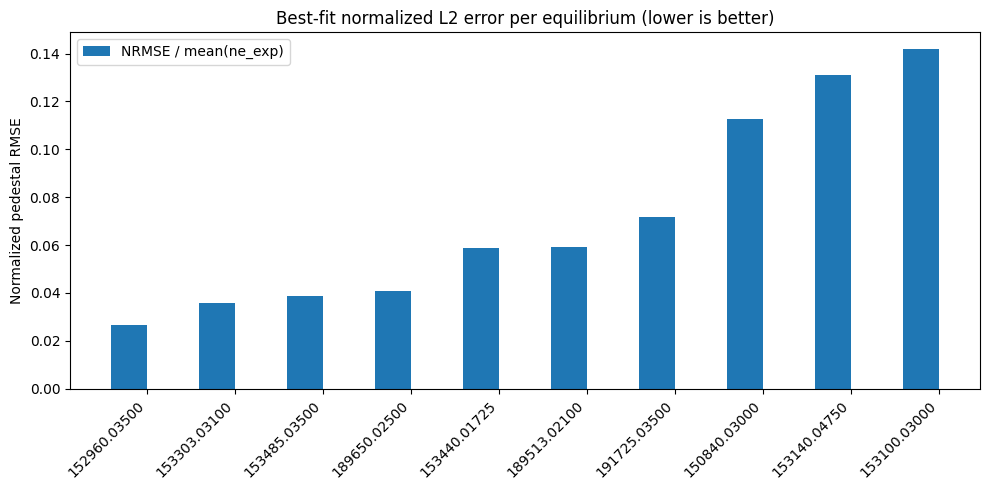

In [9]:
# Characterize L2 distance (pedestal RMSE) between each model run and the
# corresponding experimental p-file ne profile. For each equilibrium pick the
# best (lowest L2) parameter combination, then normalize the L2 across shots so
# they can be compared on the same scale.
#
# Normalizations reported (per equilibrium):
#   - rmse_abs   : raw RMSE on the pedestal grid, m^-3
#   - nrmse_mean : rmse_abs / mean(ne_pfile_ped)            -> relative error
#   - nrmse_peak : rmse_abs / max(ne_pfile_ped)             -> error vs. peak
#   - nrmse_rng  : rmse_abs / (max - min)(ne_pfile_ped)     -> error vs. pedestal step
# We use nrmse_mean as the primary cross-shot metric (unitless, intuitive).

import re
from scipy.interpolate import interp1d

scan_success_dir = Path('scan_results_Neumann_noerr/') # reset if you change the name of the scan_success_dir

# Same pedestal psi_N grid as scan_free_parameters.ipynb (psi_N_inner_boundary = 0.85).
psi_ped = np.linspace(0.85, 1.0, 200)

# Helper: read ne(psi_N) from a p-file (mirrors scan_free_parameters cell 7).
def read_pfile_ne(path):
    psi_arr, ne_arr = [], []
    in_ne_block = False
    with open(path) as f:
        for line in f:
            if '3 N Z A' in line:
                break
            if line.startswith('201'):
                in_ne_block = 'ne(10^20/m^3)' in line
                continue
            if in_ne_block:
                psi, val, _ = line.split()
                psi_arr.append(float(psi))
                ne_arr.append(float(val))
    return np.array(psi_arr), np.array(ne_arr) * 1e20  # m^-3


def best_l2_for_equilibrium(mhd_fp, kprof_fp, eq_dir, psi_ped):
    """Return (best_record, all_records) for one equilibrium."""

    # Reference model instance: only needed to build psi_N -> x mapping for this
    # equilibrium. Parameter values are arbitrary; we just need the geometry.
    ref = saarelma_connor(
        P_tot_e=P_tot_e,
        alpha_crit=alpha_crits[0],
        C_KBM=C_KBMs[0],
        De_chie_etg=De_chie_etgs[0],
        nFC_x0=nFC_x0s[0],
        mhd_fp=mhd_fp,
        kprof_fp=kprof_fp,
        verbose=False,
    )
    psi_to_x = interp1d(
        ref.psi_N_pres,
        ref.r_psi - ref.r_psi[-1],
        kind='linear', bounds_error=False, fill_value='extrapolate',
    )
    x_ped = psi_to_x(psi_ped)

    # Experimental ne on the pedestal psi grid.
    psi_pfile, ne_pfile = read_pfile_ne(kprof_fp)
    ne_pfile_ped = interp1d(
        psi_pfile, ne_pfile, kind='linear',
        bounds_error=False, fill_value='extrapolate',
    )(psi_ped)

    # Normalization scales derived from the experimental pedestal profile.
    ne_mean = float(np.mean(ne_pfile_ped))
    ne_peak = float(np.max(ne_pfile_ped))
    ne_rng = float(np.max(ne_pfile_ped) - np.min(ne_pfile_ped))

    pattern = re.compile(r"_([a-zA-Z])([\d.eE+-]+)")
    records = []
    for npy_path in eq_dir.glob('ne_*.npy'):
        pairs = pattern.findall(npy_path.stem)
        params = {letter: float(num) for letter, num in pairs}
        sol = np.load(npy_path, allow_pickle=True).item()
        ne_pred_ped = interp1d(
            sol['x'], sol['y'], kind='linear',
            bounds_error=False, fill_value='extrapolate',
        )(x_ped)
        # Drop NaN/inf points (degenerate solves) from the comparison.
        good = np.isfinite(ne_pred_ped) & np.isfinite(ne_pfile_ped)
        if not np.any(good):
            continue
        rmse_abs = float(np.sqrt(np.mean((ne_pred_ped[good] - ne_pfile_ped[good]) ** 2)))
        records.append({
            'alpha_crit':  params.get('a'),
            'C_KBM':       params.get('C'),
            'De_chie_etg': params.get('D'),
            'nFC_x0':      params.get('n'),
            'psi_inner':   params.get('b'),  # explicit psi_N_inner_boundary
            'rmse_abs':    rmse_abs,
            'nrmse_mean':  rmse_abs / ne_mean if ne_mean > 0 else np.nan,
            'nrmse_peak':  rmse_abs / ne_peak if ne_peak > 0 else np.nan,
            'nrmse_rng':   rmse_abs / ne_rng if ne_rng > 0 else np.nan,
            'ne_pred_ped': ne_pred_ped,
        })

    if not records:
        return None, [], {
            'x_ped': x_ped,
            'ne_pfile_ped': ne_pfile_ped,
            'ne_mean': ne_mean,
            'ne_peak': ne_peak,
            'ne_rng': ne_rng,
        }

    records.sort(key=lambda r: r['rmse_abs'])
    return records[0], records, {
        'x_ped': x_ped,
        'ne_pfile_ped': ne_pfile_ped,
        'ne_mean': ne_mean,
        'ne_peak': ne_peak,
        'ne_rng': ne_rng,
    }


# Walk every equilibrium that has successful runs on disk and find its best fit.
best_per_equilibrium = []
all_records_per_equilibrium = {}
context_per_equilibrium = {}

for mhd_fp, kprof_fp in equilibria:
    eq_tag = Path(mhd_fp).name[1:]
    eq_dir = scan_success_dir / eq_tag
    if not eq_dir.exists() or not any(eq_dir.glob('ne_*.npy')):
        print(f"[skip] No successful runs found for equilibrium {eq_tag}")
        continue

    best, all_records, ctx = best_l2_for_equilibrium(mhd_fp, kprof_fp, eq_dir, psi_ped)
    if best is None:
        print(f"[skip] All runs degenerate for equilibrium {eq_tag}")
        continue

    best['equilibrium'] = eq_tag
    best['n_runs'] = len(all_records)
    best['ne_peak_exp'] = ctx['ne_peak']
    best['ne_mean_exp'] = ctx['ne_mean']
    best_per_equilibrium.append(best)
    all_records_per_equilibrium[eq_tag] = all_records
    context_per_equilibrium[eq_tag] = ctx

# Rank equilibria by the primary cross-shot metric (nrmse_mean).
best_per_equilibrium.sort(key=lambda r: r['nrmse_mean'])

header = (f"{'rank':>4}  {'equilibrium':>14}  {'n_runs':>6}  "
          f"{'alpha_crit':>10}  {'C_KBM':>8}  {'De_chie_etg':>11}  {'nFC_x0':>12}  {'psi_inner':>10}  "
          f"{'rmse_abs (m^-3)':>16}  {'nrmse_mean':>10}  {'nrmse_peak':>10}  {'nrmse_rng':>10}")
print(header)
print('-' * len(header))
for rank, r in enumerate(best_per_equilibrium, start=1):
    psi_str = f"{r['psi_inner']:.4f}" if r['psi_inner'] is not None else "n/a"
    print(f"{rank:>4}  {r['equilibrium']:>14}  {r['n_runs']:>6d}  "
          f"{r['alpha_crit']:>10.3g}  {r['C_KBM']:>8.3g}  "
          f"{r['De_chie_etg']:>11.3g}  {r['nFC_x0']:>12.3g}  {psi_str:>10}  "
          f"{r['rmse_abs']:>16.3e}  {r['nrmse_mean']:>10.3e}  "
          f"{r['nrmse_peak']:>10.3e}  {r['nrmse_rng']:>10.3e}")

# Bar chart: normalized best-fit error per equilibrium for cross-shot comparison.
if best_per_equilibrium:
    labels = [r['equilibrium'] for r in best_per_equilibrium]
    nrmse_mean = [r['nrmse_mean'] for r in best_per_equilibrium]
    nrmse_peak = [r['nrmse_peak'] for r in best_per_equilibrium]

    x = np.arange(len(labels))
    width = 0.4

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(x - width / 2, nrmse_mean, width, label='NRMSE / mean(ne_exp)')
    # ax.bar(x + width / 2, nrmse_peak, width, label='NRMSE / peak(ne_exp)')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_ylabel('Normalized pedestal RMSE')
    ax.set_title('Best-fit normalized L2 error per equilibrium (lower is better)')
    ax.legend()
    plt.tight_layout()
    plt.show()

/Users/nelsonlab/.conda/envs/firedrake/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


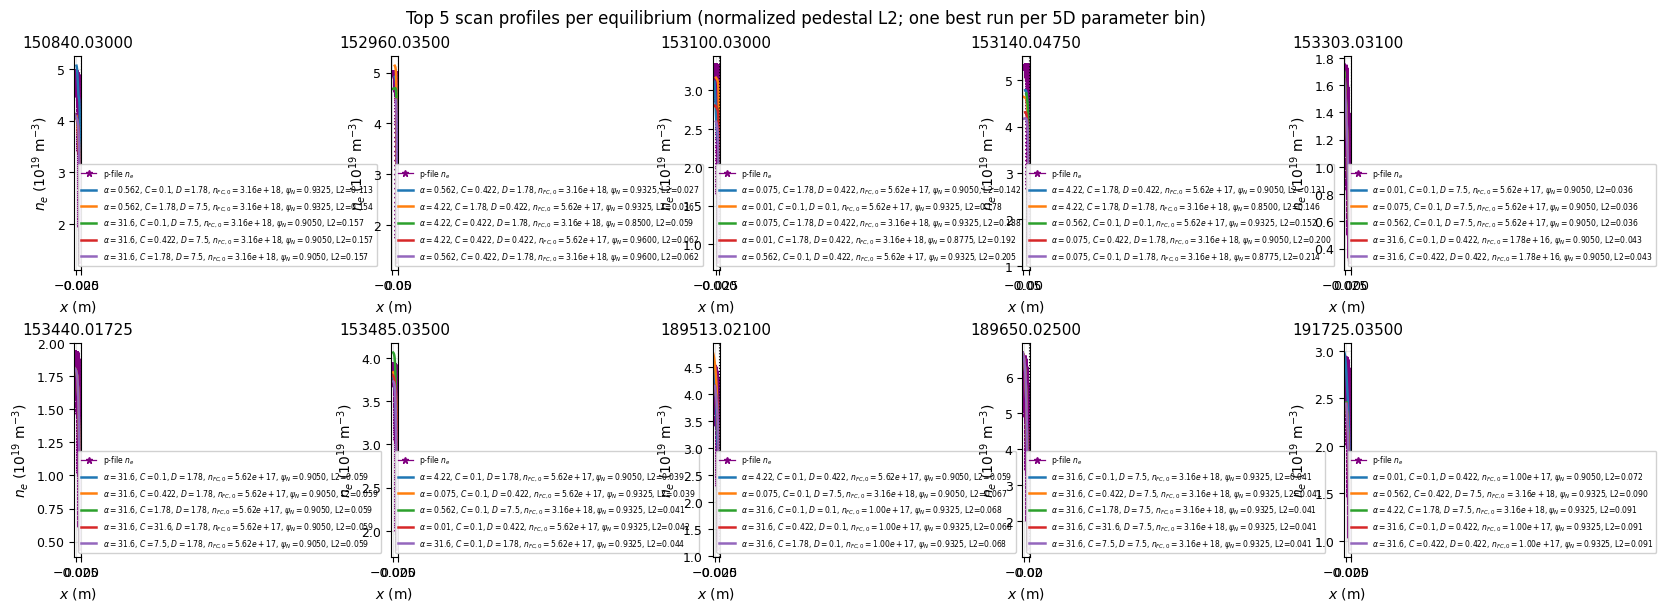

In [10]:
# Top-5 n_e profiles per equilibrium (lowest normalized pedestal L2), one panel each.
# Requires: scan cell, config cell, and cell 7 (read_pfile_ne).
import re
from scipy.interpolate import interp1d

pattern = re.compile(r"_([a-zA-Z])([\d.eE+-]+)")
psi_ped_grid = np.linspace(0.85, 1.0, 200)

param_values = [
    np.round(alpha_crits.astype(float), 3),
    np.round(C_KBMs.astype(float), 3),
    np.round(De_chie_etgs.astype(float), 3),
    np.round(nFC_x0s.astype(float), 3),
    np.round(np.linspace(0.85, 0.96, N), 3),
]


def _record_to_bins(record5):
    """Map one run to 5 scan-bin indices, or None if any parameter is off-grid."""
    bins = []
    for d in range(5):
        grid = param_values[d]
        val = float(record5[d])
        i = int(np.argmin(np.abs(grid - val)))
        if d == 4:
            on_grid = np.isclose(grid[i], val, atol=5e-4)
        elif d == 3:
            on_grid = np.isclose(grid[i], val, rtol=1e-3)
        else:
            on_grid = np.isclose(grid[i], val, rtol=0, atol=1e-6)
        if not on_grid:
            return None
        bins.append(i)
    return tuple(bins)


def top_profiles_for_equilibrium(mhd_fp, kprof_fp, eq_dir, n_top=5):
    """Best (lowest L2) on-grid run per 5D bin, then return the n_top overall."""
    ref = saarelma_connor(
        P_tot_e=P_tot_e,
        alpha_crit=alpha_crits[0],
        C_KBM=C_KBMs[0],
        De_chie_etg=De_chie_etgs[0],
        nFC_x0=nFC_x0s[0],
        mhd_fp=mhd_fp,
        kprof_fp=kprof_fp,
        verbose=False,
    )
    psi_to_x = interp1d(
        ref.psi_N_pres, ref.r_psi - ref.r_psi[-1],
        kind="linear", bounds_error=False, fill_value="extrapolate",
    )
    x_to_psi = interp1d(
        ref.r_psi - ref.r_psi[-1], ref.psi_N_pres,
        kind="linear", bounds_error=False, fill_value="extrapolate",
    )

    psi_pfile, ne_pfile = read_pfile_ne(kprof_fp)
    x_ped_grid = psi_to_x(psi_ped_grid)
    ne_pfile_on_ped = interp1d(
        psi_pfile, ne_pfile, kind="linear",
        bounds_error=False, fill_value="extrapolate",
    )(psi_ped_grid)
    mean_ne_pfile = float(np.mean(ne_pfile_on_ped))

    profile_runs = []
    for npy_path in sorted(eq_dir.glob("ne_*.npy")):
        pairs = pattern.findall(npy_path.stem)
        params = {letter: float(num) for letter, num in pairs}
        record5 = [params.get("a"), params.get("C"), params.get("D"),
                   params.get("n"), params.get("b")]
        bins5 = _record_to_bins(record5)
        if bins5 is None:
            continue

        sol = np.load(npy_path, allow_pickle=True).item()
        x_sol = np.asarray(sol["x"], dtype=float)
        ne_sol = np.asarray(sol["y"], dtype=float)
        ne_pred_on_ped = interp1d(
            x_sol, ne_sol, kind="linear", bounds_error=False, fill_value="extrapolate",
        )(x_ped_grid)
        l2_norm = float(
            np.sqrt(np.mean((ne_pred_on_ped - ne_pfile_on_ped) ** 2)) / mean_ne_pfile
        )

        label = (
            rf"$\alpha={params['a']:.3g}$, $C={params['C']:.3g}$, $D={params['D']:.3g}$, "
            rf"$n_{{FC,0}}={params['n']:.2e}$, $\psi_N={params['b']:.4f}$, "
            rf"L2={l2_norm:.3f}"
        )
        entry = dict(l2=l2_norm, label=label, x=x_sol, ne=ne_sol, bins5=bins5)
        prev = next((r for r in profile_runs if r["bins5"] == bins5), None)
        if prev is None or l2_norm < prev["l2"]:
            if prev is not None:
                profile_runs.remove(prev)
            profile_runs.append(entry)

    profile_runs.sort(key=lambda r: r["l2"])
    n_show = min(n_top, len(profile_runs))
    return profile_runs[:n_show], dict(
        psi_pfile=psi_pfile,
        ne_pfile=ne_pfile,
        x_to_psi=x_to_psi,
    )


panels = []
for mhd_fp, kprof_fp in equilibria:
    eq_tag = Path(mhd_fp).name[1:]
    eq_dir = scan_success_dir / eq_tag
    if not eq_dir.exists() or not any(eq_dir.glob("ne_*.npy")):
        print(f"[skip] No successful runs for equilibrium {eq_tag}")
        continue
    top, ctx = top_profiles_for_equilibrium(mhd_fp, kprof_fp, eq_dir, n_top=5)
    if not top:
        print(f"[skip] No on-grid profiles for equilibrium {eq_tag}")
        continue
    panels.append((eq_tag, top, ctx))

if not panels:
    print("No equilibria with on-grid scan profiles — run the scan cell first.")
else:
    n_eq = len(panels)
    ncols = min(5, n_eq)
    nrows = int(np.ceil(n_eq / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(3.2 * ncols, 3.0 * nrows),
        constrained_layout=True,
        squeeze=False,
    )

    for idx, (eq_tag, top, ctx) in enumerate(panels):
        ax = axes.flat[idx]
        psi_pfile = ctx["psi_pfile"]
        ne_pfile = ctx["ne_pfile"]
        x_to_psi = ctx["x_to_psi"]

        x_lo = min(r["x"].min() for r in top)
        x_hi = max(r["x"].max() for r in top)
        x_plot = np.linspace(x_lo, x_hi, 250)
        psi_on_plot = x_to_psi(x_plot)
        ne_pfile_on_x = interp1d(
            psi_pfile, ne_pfile, kind="linear",
            bounds_error=False, fill_value="extrapolate",
        )(psi_on_plot)
        ax.plot(
            x_plot, ne_pfile_on_x / 1e19, "*-", color="purple", ms=5, lw=0.9,
            label="p-file $n_e$",
        )

        for i, run in enumerate(top):
            ax.plot(
                run["x"], run["ne"] / 1e19,
                color=plt.cm.tab10(i), lw=1.8, label=run["label"],
            )
        ax.axvline(0, color="k", ls=":", lw=0.8)
        ax.set_title(eq_tag, fontsize=11)
        ax.set_xlabel(r"$x$ (m)", fontsize=10)
        ax.set_ylabel(r"$n_e$ ($10^{19}$ m$^{-3}$)", fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.tick_params(labelsize=9)
        ax.legend(fontsize=5.5, loc="lower left", framealpha=0.9)

    for j in range(n_eq, nrows * ncols):
        axes.flat[j].set_visible(False)

    fig.suptitle(
        "Top 5 scan profiles per equilibrium "
        "(normalized pedestal L2; one best run per 5D parameter bin)",
        fontsize=12,
    )
    plt.savefig("ne_top5_per_equilibrium.png", dpi=300)
    plt.show()